# 02 — Analyse des variables et modèle de référence

**Projet :** pipeline MLOps de prédiction du risque de crédit — *Abdessamad Abouchraa, Master Data & AI*

Ce notebook complète l'EDA :
1. il mesure le **pouvoir prédictif de chaque variable**, prise isolément ;
2. il construit un **modèle de référence** (régression logistique scikit-learn) sur le même jeu gold et avec un
   découpage comparable à celui du pipeline, pour vérifier les performances obtenues avec SparkML (AUC 0,932) ;
3. il analyse les **coefficients**, le **calibrage** des probabilités et le choix des **seuils de risque** utilisés par
   l'API (`low` < 0,2 ≤ `medium` < 0,5 ≤ `high`).

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from data_loader import load_gold, NUMERIC, NUMERIC_RAW, NUMERIC_DERIVED, CATEGORICAL, TARGET

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
pd.set_option("display.float_format", lambda v: f"{v:,.3f}".replace(",", " "))
C0, C1 = "#3b82f6", "#ef4444"          # sans défaut / défaut

df, source = load_gold()
print("Source :", source)
df.head()

Source : instantané gold versionné par DVC (data/gold_snapshot/gold.parquet), 147 257 lignes


,application_id,event_date,age,income,employment_years,loan_amount,loan_term_months,interest_rate,credit_score,num_open_accounts,num_late_payments,debt_to_income,payment_to_income,late_per_account,home_ownership,loan_purpose,label,snapshot_date
0,000212df-d57a-4790-b4b6-e08eabe9f310,2026-11-17,34,34 744.130,7,25 045.770,36,8.670,717,6,1,0.721,0.261,0.143,OWN,car,0,2026-11-17
1,000294a2-77e3-4223-8a4c-6b6ab69d2514,2026-11-17,68,32 465.270,30,19 026.010,48,16.990,795,2,0,0.586,0.171,0.000,MORTGAGE,education,0,2026-11-17
2,0002aa90-902e-4c66-9868-94e44d1e1e14,2026-11-17,45,24 081.010,0,7 164.510,24,13.300,511,3,0,0.298,0.169,0.000,RENT,car,1,2026-11-17
3,0005cb36-cbe4-4dfe-92ee-19e4df995156,2026-11-17,43,8 000.000,35,5 154.200,24,12.050,843,9,0,0.644,0.361,0.000,RENT,debt,0,2026-11-17
4,0006db80-de06-4c92-9b47-d8fdd4879eb3,2026-11-17,30,22 853.950,18,34 748.190,12,11.630,668,11,0,1.520,1.697,0.000,MORTGAGE,debt,1,2026-11-17


## 1. Pouvoir prédictif de chaque variable

In [2]:
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import roc_auc_score

sample = df.sample(min(len(df), 40_000), random_state=0)       # l'information mutuelle est coûteuse
mi = mutual_info_classif(sample[NUMERIC], sample[TARGET], random_state=0)
univ = pd.DataFrame({
    "AUC univariée": [max(roc_auc_score(df[TARGET], df[c]), 1 - roc_auc_score(df[TARGET], df[c])) for c in NUMERIC],
    "information mutuelle": mi,
    "sens": ["↑ risque" if roc_auc_score(df[TARGET], df[c]) > .5 else "↓ risque" for c in NUMERIC],
}, index=NUMERIC).sort_values("AUC univariée", ascending=False)
univ

,AUC univariée,information mutuelle,sens
credit_score,0.793,0.083,↓ risque
debt_to_income,0.760,0.085,↑ risque
payment_to_income,0.724,0.056,↑ risque
income,0.705,0.050,↓ risque
loan_amount,0.664,0.024,↑ risque
num_late_payments,0.583,0.012,↑ risque
late_per_account,0.580,0.009,↑ risque
employment_years,0.502,0.002,↓ risque
interest_rate,0.502,0.000,↑ risque
loan_term_months,0.502,0.002,↓ risque


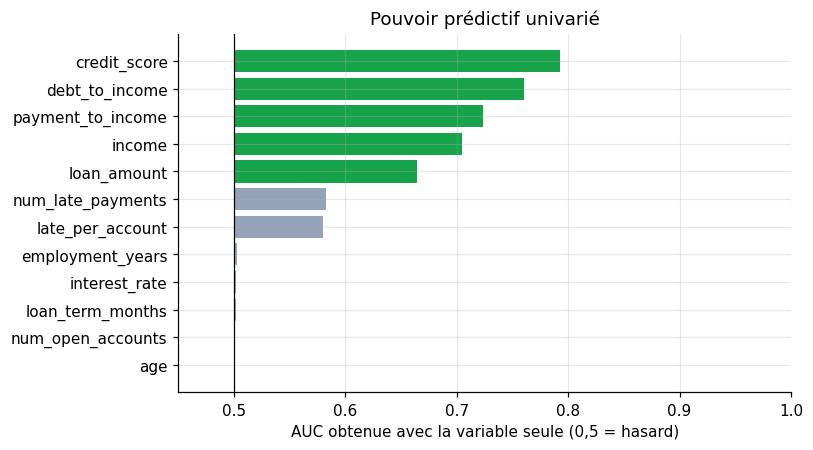

In [3]:
fig, ax = plt.subplots(figsize=(7.5, 4.2))
u = univ.sort_values("AUC univariée")
ax.barh(u.index, u["AUC univariée"] - .5, left=.5, color=["#16a34a" if v > .6 else "#94a3b8" for v in u["AUC univariée"]])
ax.axvline(.5, color="black", lw=.8)
ax.set_xlim(.45, 1); ax.set_xlabel("AUC obtenue avec la variable seule (0,5 = hasard)")
ax.set_title("Pouvoir prédictif univarié")
plt.tight_layout(); plt.show()

**Constat.** Le **score de crédit** est la variable la plus informative à elle seule (AUC 0,79), suivi du **ratio
d'endettement** `debt_to_income` (0,76) et de `payment_to_income` (0,72), puis du **revenu** et du **montant**
(0,70 et 0,66), qui sont les composantes de ce ratio. Les **retards de paiement** viennent ensuite (0,58).
L'âge, l'ancienneté, la durée, le taux d'intérêt et le nombre de comptes sont au niveau du hasard (AUC ≈ 0,50).

## 2. Modèle de référence : régression logistique

Le découpage reproduit le principe du pipeline : il est **déterministe**, fondé sur un hachage de `application_id`
(80 % entraînement / 20 % test), pour que les résultats ne dépendent pas d'un tirage aléatoire. Le hachage utilisé ici
(MD5) n'est pas celui de Spark : les deux jeux de test sont différents mais de même nature.

In [4]:
import hashlib
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_curve
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

bucket = df["application_id"].map(lambda s: int(hashlib.md5(s.encode()).hexdigest(), 16) % 100)
train, test = df[bucket < 80], df[bucket >= 80]
print(f"entraînement : {len(train):,}  |  test : {len(test):,}".replace(",", " "))

model = Pipeline([
    ("prep", ColumnTransformer([("num", StandardScaler(), NUMERIC),
                                # drop="first" : une modalité de référence par variable, sinon les indicatrices
                                # sont redondantes avec l'intercept et leurs coefficients ne sont pas interprétables
                                ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), CATEGORICAL)])),
    ("clf", LogisticRegression(C=1 / 0.01, max_iter=1000)),
])
model.fit(train[NUMERIC + CATEGORICAL], train[TARGET])
proba = model.predict_proba(test[NUMERIC + CATEGORICAL])[:, 1]
auc, ap = roc_auc_score(test[TARGET], proba), average_precision_score(test[TARGET], proba)
pd.DataFrame({"AUC": [auc, 0.9321], "AUC-PR": [ap, 0.7797]},
             index=["Régression logistique scikit-learn (ce notebook)", "Régression logistique SparkML (pipeline, champion v3)"])

entraînement : 117 644  |  test : 29 613


,AUC,AUC-PR
Régression logistique scikit-learn (ce notebook),0.935,0.781
"Régression logistique SparkML (pipeline, champion v3)",0.932,0.780


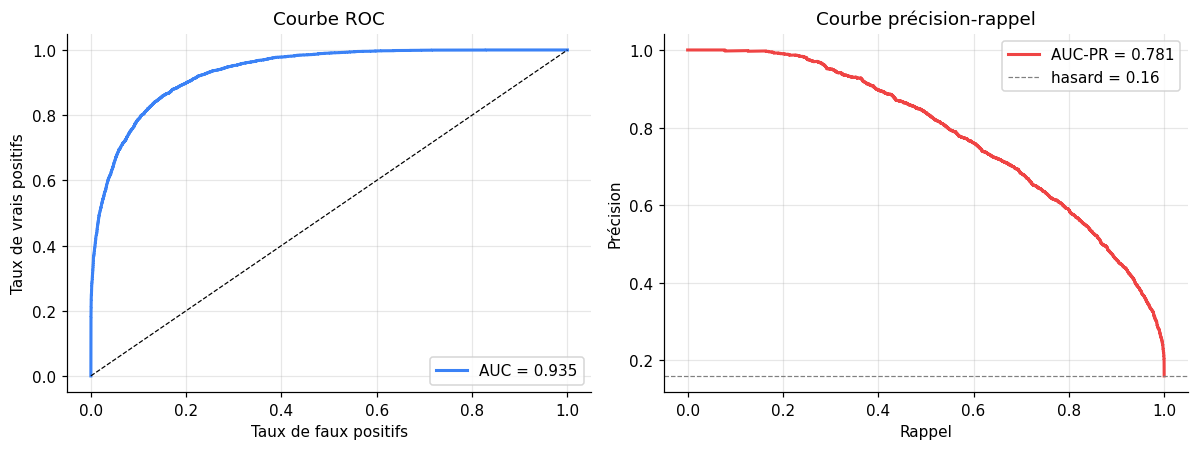

In [5]:
fpr, tpr, _ = roc_curve(test[TARGET], proba)
prec, rec, _ = precision_recall_curve(test[TARGET], proba)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].plot(fpr, tpr, color=C0, lw=2, label=f"AUC = {auc:.3f}"); axes[0].plot([0, 1], [0, 1], "k--", lw=.8)
axes[0].set_xlabel("Taux de faux positifs"); axes[0].set_ylabel("Taux de vrais positifs"); axes[0].set_title("Courbe ROC")
axes[1].plot(rec, prec, color=C1, lw=2, label=f"AUC-PR = {ap:.3f}")
axes[1].axhline(test[TARGET].mean(), color="gray", ls="--", lw=.8, label=f"hasard = {test[TARGET].mean():.2f}")
axes[1].set_xlabel("Rappel"); axes[1].set_ylabel("Précision"); axes[1].set_title("Courbe précision-rappel")
for ax in axes: ax.legend(loc="lower right" if ax is axes[0] else "upper right")
plt.tight_layout(); plt.show()

**Constat.** Le modèle de référence scikit-learn obtient des performances **équivalentes** à celles de la régression
logistique entraînée par le pipeline SparkML. Cela valide le pipeline : les résultats obtenus dans MLflow ne sont pas
un artefact de l'implémentation Spark.

## 3. Interprétation : coefficients standardisés

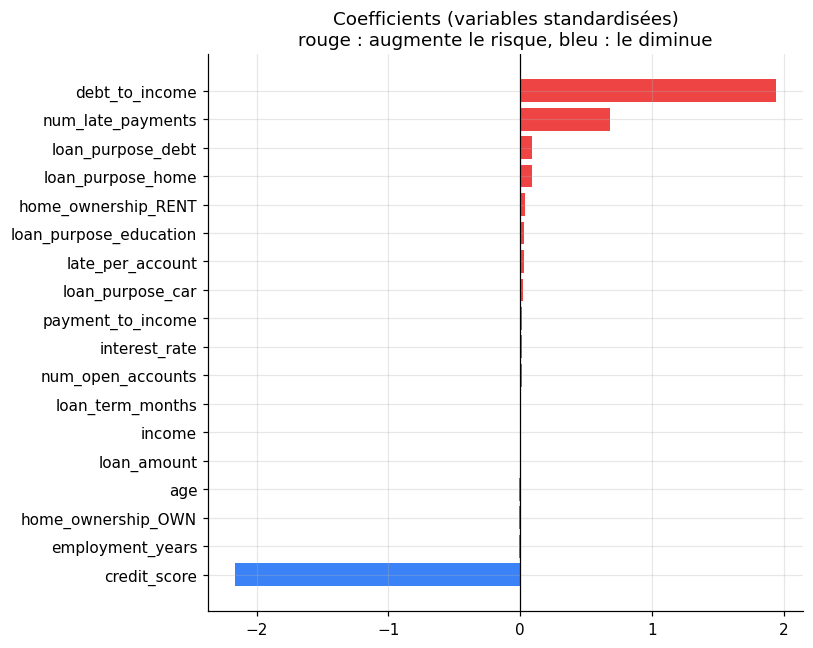

In [6]:
names = model.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(model.named_steps["clf"].coef_[0], index=[n.split("__", 1)[1] for n in names]).sort_values()
fig, ax = plt.subplots(figsize=(7.5, 6))
ax.barh(coefs.index, coefs.values, color=[C1 if v > 0 else C0 for v in coefs.values])
ax.axvline(0, color="black", lw=.8)
ax.set_title("Coefficients (variables standardisées)\nrouge : augmente le risque, bleu : le diminue")
plt.tight_layout(); plt.show()

**Constat.** Trois variables portent l'essentiel du modèle : le **score de crédit** (fort coefficient négatif), le
**ratio d'endettement** `debt_to_income` (fort coefficient positif) et les **retards de paiement** (positif). Toutes
les autres ont un coefficient proche de zéro :
- le **revenu** et le **montant**, pourtant informatifs seuls, n'apportent plus rien une fois `debt_to_income` connu :
  leur information est déjà contenue dans ce ratio ;
- `payment_to_income` et `late_per_account`, redondantes avec `debt_to_income` et `num_late_payments`, sont neutralisées
  par la régularisation ;
- les modalités de `home_ownership` et `loan_purpose` (par rapport à leur modalité de référence) n'ont aucun effet.

C'est cohérent avec la façon dont le générateur définit le risque (à partir du score, de l'endettement et des retards) :
le modèle **retrouve les vrais facteurs de risque**. Il est donc interprétable, un atout pour justifier une décision.

## 4. Calibrage des probabilités

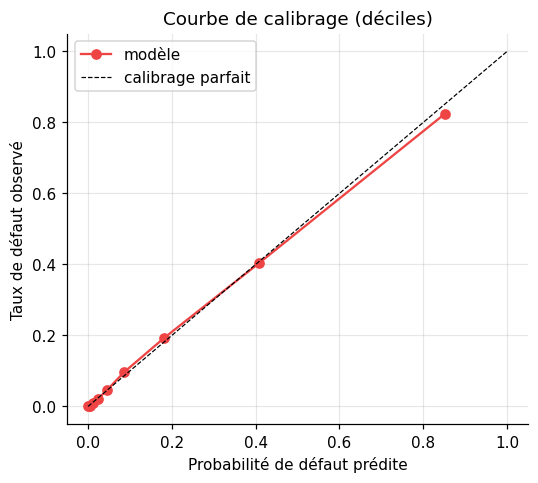

In [7]:
cal = pd.DataFrame({"proba": proba, "y": test[TARGET].values})
cal["tranche"] = pd.qcut(cal["proba"], 10, duplicates="drop")
g = cal.groupby("tranche", observed=True).agg(prédite=("proba", "mean"), observée=("y", "mean"))
fig, ax = plt.subplots(figsize=(5, 4.5))
ax.plot(g["prédite"], g["observée"], marker="o", color=C1, label="modèle")
ax.plot([0, 1], [0, 1], "k--", lw=.8, label="calibrage parfait")
ax.set_xlabel("Probabilité de défaut prédite"); ax.set_ylabel("Taux de défaut observé")
ax.set_title("Courbe de calibrage (déciles)"); ax.legend()
plt.tight_layout(); plt.show()

**Constat.** Les points suivent la diagonale : une probabilité prédite de 30 % correspond bien à environ 30 % de
défauts observés. Les probabilités renvoyées par l'API (`default_probability`) peuvent donc être lues **comme de vraies
probabilités**, ce qui donne un sens aux seuils de risque.

## 5. Seuils de risque utilisés par l'API

In [8]:
levels = pd.cut(proba, [0, .2, .5, 1], labels=["low (< 0,2)", "medium (0,2 – 0,5)", "high (≥ 0,5)"], include_lowest=True)
seg = pd.DataFrame({"niveau": levels, "y": test[TARGET].values}).groupby("niveau", observed=True)["y"].agg(["size", "mean"])
seg.columns = ["demandes", "taux de défaut réel"]
seg["part des demandes"] = seg["demandes"] / seg["demandes"].sum()
seg["part des défauts captés"] = seg["demandes"] * seg["taux de défaut réel"] / test[TARGET].sum()
seg

,demandes,taux de défaut réel,part des demandes,part des défauts captés
niveau,,,,
"low (< 0,2)",22690,0.037,0.766,0.178
"medium (0,2 – 0,5)",3297,0.335,0.111,0.233
"high (≥ 0,5)",3626,0.768,0.122,0.589


**Constat.** Les trois niveaux de l'API séparent bien les risques :
- `low` regroupe environ **77 %** des demandes avec un taux de défaut d'environ **4 %** ;
- `medium` (environ 11 % des demandes) a un taux de défaut d'environ **34 %** : ce sont les dossiers à étudier, comme
  l'indique l'interface Streamlit ;
- `high` (environ 12 % des demandes) a un taux de défaut d'environ **77 %** et capte à lui seul près de **60 %** des
  défauts réels.

Avec les niveaux `medium` et `high` réunis, on signale environ 23 % des demandes et on capte plus de 80 % des défauts.

## Conclusion

- Le défaut est expliqué principalement par **le score de crédit, les retards de paiement et l'endettement**.
- Une **régression logistique** régularisée sur variables standardisées suffit à atteindre une AUC d'environ 0,93,
  en accord avec le champion du pipeline ; ses coefficients sont interprétables et ses probabilités bien calibrées.
- Ces résultats valident les choix faits dans le pipeline MLOps : qualité des données garantie en amont, métriques
  adaptées au déséquilibre, comparaison de plusieurs modèles et promotion du meilleur.